In [1]:
import OMPython
import os
import logging
import pandas as pd
import DyMat
import numpy as np
from matplotlib import pyplot as plt

In [2]:
logging.getLogger("OMPython").setLevel(logging.ERROR)
omc = OMPython.OMCSessionLocal()
omc.sendExpression("loadFile(\"/home/wspark/projects/ThermoPower/ThermoPower/package.mo\")")
omc.sendExpression("loadFile(\"/home/wspark/projects/AmazonRunScripts/ReferenceOM/package.mo\")")
RESULT_DIR = "/home/wspark/projects/OMResults/BasicProfile"
omc.sendExpression(f'cd("{RESULT_DIR}")')

'/home/wspark/projects/OMResults/BasicProfile'

In [ ]:
"Simulation setting"

var_map_PID = {
    "T_helium": "sens_T_He.T",
    "T_steam": "sens_T_steam.T",
    "P_steam": "sens_P_steam.p",
    "f_grid": "sens_frequency.f",
    "V_condenser": "Condenser.condenserShell.ratio_VvVtot",
    "rho_tot": "reactorPower_Avg.rho",
    "rho_Xe": "reactorPower_Avg.rho_Xe",
    "rho_ext": "reactorPower_Avg.rho_ext",
    "rho_feedback": "reactorPower_Avg.rho_feedback",
    "P_mech": "generator.Pm",
    "P_elec": "generator.Pe",
    "P_reactor": "reactorPower_Avg.P",
    "P_demand": "LoadDemand.y",
    "rho_der_y": "RhoDerivative.y",
    "T_fuel_hot": "Fuel_mixture_Hot.Tmax",
    "T_fuel_avg": "Fuel_mixture_Avg.Tmax",
    "PID_blower_y": "PID_blower.y",
    "PID_fwpp_y": "PID_fwpp.y",
    "PID_cdpp_y": "PID_cdpp.y",
    "PID_reactivity_y": "PID_reactivity.y",
    "PID_valve_y": "PID_valve.y",
}

var_map_SMC = {
    "T_helium": "sens_T_He.T",
    "T_steam": "sens_T_steam.T",
    "P_steam": "sens_P_steam.p",
    "f_grid": "sens_frequency.f",
    "V_condenser": "Condenser.condenserShell.ratio_VvVtot",
    "rho_tot": "reactorPower_Avg.rho",
    "rho_Xe": "reactorPower_Avg.rho_Xe",
    "rho_ext": "reactorPower_Avg.rho_ext",
    "rho_feedback": "reactorPower_Avg.rho_feedback",
    "P_mech": "generator.Pm",
    "P_elec": "generator.Pe",
    "P_reactor": "reactorPower_Avg.P",
    "P_demand": "LoadDemand.y",
    "rho_der_y": "RhoDerivative.y",
    "T_fuel_hot": "Fuel_mixture_Hot.Tmax",
    "T_fuel_avg": "Fuel_mixture_Avg.Tmax",
    "SMC_blower_y": "SMC_blower.y",
    "SMC_fwpp_y": "SMC_fwpp.y",
    "SMC_cdpp_y": "SMC_cdpp.y",
    "SMC_reactivity_y": "SMC_reactivity.y",
    "SMC_valve_y": "SMC_valve.y",
}

VARS_TO_SAVE_PID = list(var_map_PID.values())
VARIABLE_FILTER_PID = "|".join(VARS_TO_SAVE_PID)
VARS_TO_SAVE_SMC = list(var_map_SMC.values())
VARIABLE_FILTER_SMC = "|".join(VARS_TO_SAVE_SMC)

STARTTIME = 0
STOPTIME = 10000
ANALYSISTIME = 5000
DT = 10
NUMOFINTERVAL = int((STOPTIME-STARTTIME)/DT)

NOMINAL_T_STEAM = 823
NOMINAL_P_STEAM = 14.3e6
NOMINAL_T_HELIUM = 1023
NOMINAL_F_GRID = 60
NOMINAL_P_DEMAND = 65.5e6

MODEL_PID = "ReferenceOM.TransientRuns.BasicProfile_PID"
MODEL_SMC = "ReferenceOM.TransientRuns.BasicProfile_SMC"

In [ ]:
"Run PID cases"

result_PID = omc.sendExpression(f"""
simulate(
    {MODEL_PID},
    stopTime={STOPTIME},
    numberOfIntervals={NUMOFINTERVAL},
    tolerance=1e-6,
    outputFormat="mat",
    fileNamePrefix="{"BasicProfile_PID"}",
    variableFilter="{VARIABLE_FILTER_PID}"
)
""")
print("  ->", result_PID["resultFile"])

# Remove unnecessary files
for filename in os.listdir(RESULT_DIR):
    path = os.path.join(RESULT_DIR, filename)
    if os.path.isfile(path) and not filename.endswith(".mat"):
        os.remove(path)

saved_vars = omc.sendExpression(
    f'readSimulationResultVars("{result_PID["resultFile"]}", false)'
)

for v in saved_vars:
    print(v)

KeyboardInterrupt: 

In [ ]:
"Run SMC cases"

result_SMC = omc.sendExpression(f"""
simulate(
    {MODEL_SMC},
    stopTime={STOPTIME},
    numberOfIntervals={NUMOFINTERVAL},
    tolerance=1e-6,
    outputFormat="mat",
    fileNamePrefix="{"BasicProfile_SMC"}",
    variableFilter="{VARIABLE_FILTER_SMC}"
)
""")
print("  ->", result_SMC["resultFile"])

for filename in os.listdir(RESULT_DIR):
    path = os.path.join(RESULT_DIR, filename)
    if os.path.isfile(path) and not filename.endswith(".mat"):
        os.remove(path)

  -> /home/wspark/projects/OMResults/BasicProfile/BasicProfile_SMC_res.mat


In [ ]:
"Load result .mat"

data = {}
mat_PID = DyMat.DyMatFile(RESULT_DIR + "/" + "BasicProfile_PID" + "_res.mat")
mat_SMC = DyMat.DyMatFile(RESULT_DIR + "/" + "BasicProfile_SMC" + "_res.mat")
time = mat_PID.abscissa("sens_T_He.T", valuesOnly=True)
idx_trim = time >= ANALYSISTIME 
time_trim = time[idx_trim]-ANALYSISTIME

data["PID"] = {}
data["SMC"] = {}
data["PID"]["time"] = time_trim
data["SMC"]["time"] = time_trim

for name, omname in var_map_PID.items():
    data["PID"][name] = mat_PID.data(omname)[idx_trim]
for name, omname in var_map_SMC.items():
    data["SMC"][name] = mat_SMC.data(omname)[idx_trim]

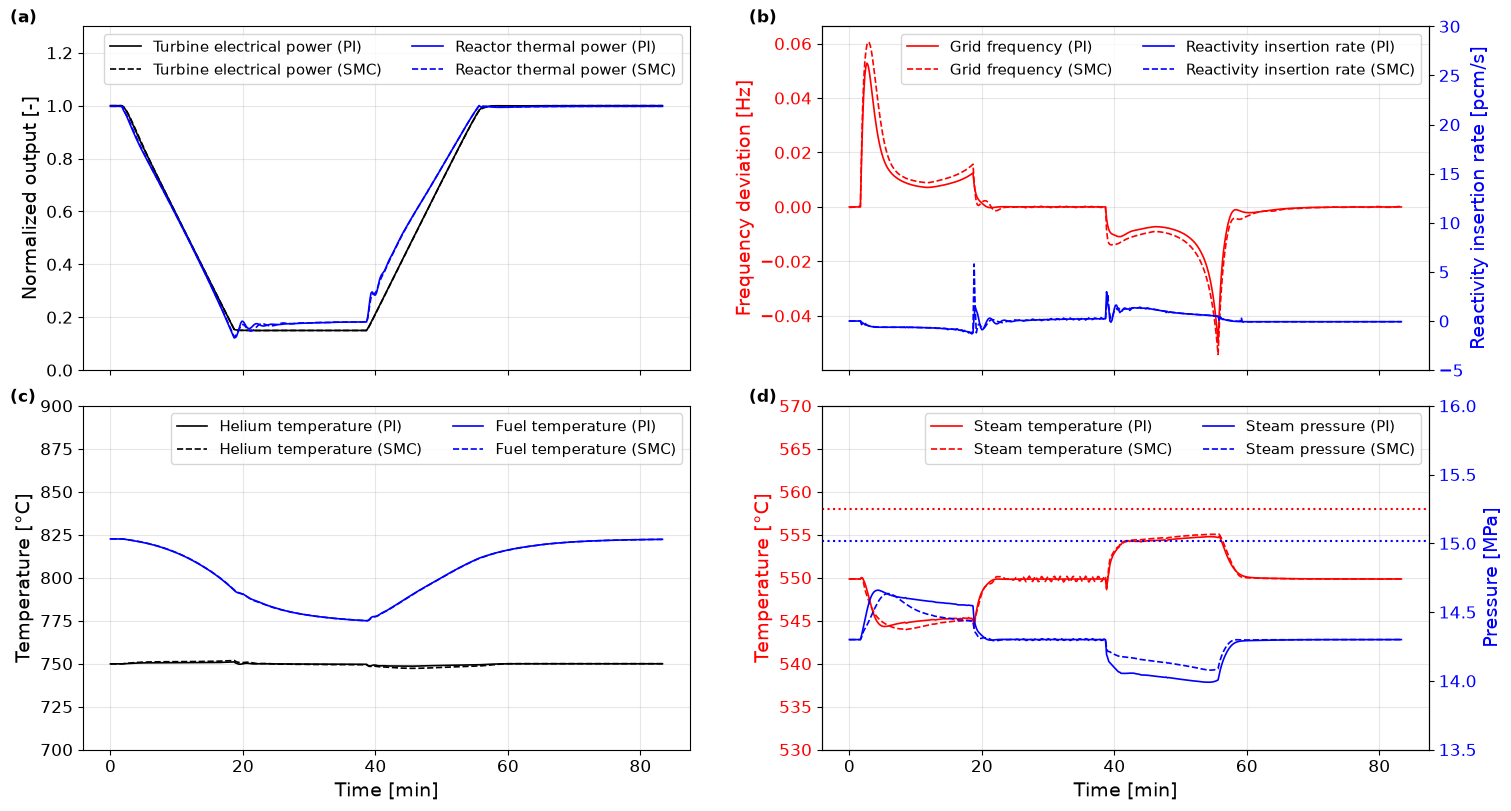

In [ ]:
"Generate figure"

figs, axs = plt.subplots(2, 2, figsize=(15,8), sharex='col', constrained_layout=True)
figs.set_constrained_layout_pads(hspace=0.01, wspace=0.06)

plt.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
})

axs[0,0].plot(data["PID"]["time"]/60, data["PID"]["P_elec"]/NOMINAL_P_DEMAND, lw=1.2, color="k", label="Turbine electrical power (PI)")
axs[0,0].plot(data["SMC"]["time"]/60, data["SMC"]["P_elec"]/NOMINAL_P_DEMAND, lw=1.2, color="k", ls='--', label="Turbine electrical power (SMC)")
axs[0,0].plot(data["PID"]["time"]/60, data["PID"]["P_reactor"]/180e6, lw=1.2, color="b", label="Reactor thermal power (PI)")
axs[0,0].plot(data["SMC"]["time"]/60, data["SMC"]["P_reactor"]/180e6, lw=1.2, color="b", ls='--', label="Reactor thermal power (SMC)")
axs[0,0].set_ylabel("Normalized output [-]")
axs[0,0].grid(alpha=0.3)
axs[0,0].set_ylim([0, 1.3])
axs[0,0].legend(ncol=2, loc=1)

ax_l = axs[0,1]
ax_r = ax_l.twinx()
ln1 = ax_l.plot(data["PID"]["time"]/60, data["PID"]["f_grid"]-NOMINAL_F_GRID, lw=1.2, color="r", label="Grid frequency (PI)")
ln2 = ax_l.plot(data["SMC"]["time"]/60, data["SMC"]["f_grid"]-NOMINAL_F_GRID, lw=1.2, color="r", ls='--', label="Grid frequency (SMC)")
ln3 = ax_r.plot(data["PID"]["time"]/60, data["PID"]["rho_der_y"]*1e5, color="b", lw=1.2, label="Reactivity insertion rate (PI)")
ln4 = ax_r.plot(data["SMC"]["time"]/60, data["SMC"]["rho_der_y"]*1e5, color="b", lw=1.2, ls='--', label="Reactivity insertion rate (SMC)")
ax_l.set_ylabel("Frequency deviation [Hz]", color="r")
ax_l.grid(alpha=0.3)
ax_l.tick_params(axis="y", labelcolor="r")
ax_r.set_ylabel("Reactivity insertion rate [pcm/s]", color="b")
ax_r.set_ylim([-5, 30])
ax_r.tick_params(axis="y", labelcolor="b")
lns = ln1+ln2+ln3+ln4
labs = [l.get_label() for l in lns]
ax_r.legend(lns, labs, ncol=2)

axs[1,0].plot(data["PID"]["time"]/60, data["PID"]["T_helium"]-273.15, color='k', lw=1.2, label="Helium temperature (PI)")
axs[1,0].plot(data["SMC"]["time"]/60, data["SMC"]["T_helium"]-273.15, color='k', lw=1.2, ls='--', label="Helium temperature (SMC)")
axs[1,0].plot(data["PID"]["time"]/60, data["PID"]["T_fuel_hot"]-273.15, color='b', lw=1.2, label="Fuel temperature (PI)")
axs[1,0].plot(data["SMC"]["time"]/60, data["SMC"]["T_fuel_hot"]-273.15, color='b', lw=1.2, ls='--', label="Fuel temperature (SMC)")
axs[1,0].legend(ncol=2)
axs[1,0].grid(alpha=0.3)
axs[1,0].set_xlabel("Time [min]")
axs[1,0].set_ylabel("Temperature [$\\degree$C]")
axs[1,0].set_ylim([700, 900])

ax_l = axs[1,1]
ax_r = ax_l.twinx()
ln1 = ax_l.plot(data["PID"]["time"]/60, data["PID"]["T_steam"]-273.15, lw=1.2, color="r", label="Steam temperature (PI)")
ln2 = ax_l.plot(data["SMC"]["time"]/60, data["SMC"]["T_steam"]-273.15, lw=1.2, color="r", ls='--', label="Steam temperature (SMC)")
ln3 = ax_l.axhline(550+8, ls=":", lw=1.5, color="r")
ln4 = ax_r.plot(data["PID"]["time"]/60, data["PID"]["P_steam"]/1e6, lw=1.2, color="b", label="Steam pressure (PI)")
ln5 = ax_r.plot(data["SMC"]["time"]/60, data["SMC"]["P_steam"]/1e6, lw=1.2, color="b", ls='--', label="Steam pressure (SMC)")
ln6 = ax_r.axhline(14.3*1.05, ls=":", lw=1.5, color="b")
ax_l.set_xlabel("Time [min]")
ax_l.set_ylabel("Temperature [$\\degree$C]", color="r")
ax_l.set_ylim([530, 570])
ax_l.grid(alpha=0.3)
ax_l.tick_params(axis="y", labelcolor="r")
ax_r.set_ylabel("Pressure [MPa]", color="b")
ax_r.set_ylim([13.5, 16])
ax_r.tick_params(axis="y", labelcolor="b")
lns = [ln1[0], ln2[0], ln4[0], ln5[0]]
labs = [l.get_label() for l in lns]
ax_l.legend(lns, labs, ncol=2)

labels = ['(a)', '(b)', '(c)', '(d)']
for ax, label in zip(axs.flat, labels):
    ax.text(
        -0.12, 1.0, label,
        transform=ax.transAxes,
        fontsize=12,
        fontweight='bold',
        va='bottom',
        ha='left'
    )

# figs.savefig("tuning_result.pdf", bbox_inches="tight")